In [1]:

import os, sys, ast, time, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from tqdm.auto import tqdm

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU only")


Mounted at /content/drive
Device: cuda | Tesla T4


In [3]:
import os, sys, ast, time, random, urllib.request, zipfile
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from tqdm.auto import tqdm
from google.colab import drive
drive.mount("/content/drive")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU only")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda | Tesla T4


In [4]:
DATA_ROOT = Path("/content/data")                       # temporary disk
OUT_ROOT  = Path("/content/drive/MyDrive/anomaly/outputs")  # saved on Drive, survives disconnects
MODEL_DIR, PRED_DIR = OUT_ROOT/"models", OUT_ROOT/"predictions"
for d in (DATA_ROOT, MODEL_DIR, PRED_DIR): d.mkdir(parents=True, exist_ok=True)

CFG = dict(window=250, hidden=80, layers=2, dropout=0.3, batch_size=64, lr=1e-3,
           max_epochs=35, patience=10, min_delta=3e-4, val_frac=0.2, grad_clip=1.0, seed=42)
print(CFG)

{'window': 250, 'hidden': 80, 'layers': 2, 'dropout': 0.3, 'batch_size': 64, 'lr': 0.001, 'max_epochs': 35, 'patience': 10, 'min_delta': 0.0003, 'val_frac': 0.2, 'grad_clip': 1.0, 'seed': 42}


In [6]:
!pip install -q kagglehub
import kagglehub, shutil

LABELS_URL = "https://raw.githubusercontent.com/khundman/telemanom/master/labeled_anomalies.csv"

if not any(DATA_ROOT.rglob("train/*.npy")):
    src = kagglehub.dataset_download("patrickfleith/nasa-anomaly-detection-dataset-smap-msl")
    print("Downloaded to:", src)
    shutil.copytree(src, DATA_ROOT, dirs_exist_ok=True)      # copy to /content/data so later cells work unchanged

if next(DATA_ROOT.rglob("labeled_anomalies.csv"), None) is None:   # fetch the labels if the Kaggle copy lacks them
    urllib.request.urlretrieve(LABELS_URL, DATA_ROOT/"labeled_anomalies.csv")

print("train files:", len(list(DATA_ROOT.rglob("train/*.npy"))), "| test files:", len(list(DATA_ROOT.rglob("test/*.npy"))))

Using Colab cache for faster access to the 'nasa-anomaly-detection-dataset-smap-msl' dataset.
Downloaded to: /kaggle/input/nasa-anomaly-detection-dataset-smap-msl
train files: 82 | test files: 82


In [9]:
def find_data(root):
    csv = next(root.rglob("labeled_anomalies.csv"))
    ok = lambda p: p.is_dir() and "__MACOSX" not in p.parts and any(p.glob("*.npy"))
    return csv, next(p for p in sorted(root.rglob("train")) if ok(p)), next(p for p in sorted(root.rglob("test")) if ok(p))

csv_path, train_dir, test_dir = find_data(DATA_ROOT)
labels = pd.read_csv(csv_path)
labels["anomaly_sequences"] = labels["anomaly_sequences"].apply(ast.literal_eval)
chan_ids = [c for c in labels.chan_id if (train_dir/f"{c}.npy").exists() and (test_dir/f"{c}.npy").exists()]
print(len(chan_ids), "channels |", labels.anomaly_sequences.apply(len).sum(), "anomaly intervals")
print(labels.groupby("spacecraft").size().to_dict())
labels.head()

82 channels | 105 anomaly intervals
{'MSL': 27, 'SMAP': 55}


,chan_id,spacecraft,anomaly_sequences,class,num_values
0,P-1,SMAP,"[[2149, 2349], [4536, 4844], [3539, 3779]]","[contextual, contextual, contextual]",8505
1,S-1,SMAP,"[[5300, 5747]]",[point],7331
2,E-1,SMAP,"[[5000, 5030], [5610, 6086]]","[contextual, contextual]",8516
3,E-2,SMAP,"[[5598, 6995]]",[point],8532
4,E-3,SMAP,"[[5094, 8306]]",[point],8307


P-1 | train (2872, 25) | test (8505, 25)
labeled anomaly intervals (test indices): [[2149, 2349], [4536, 4844], [3539, 3779]]


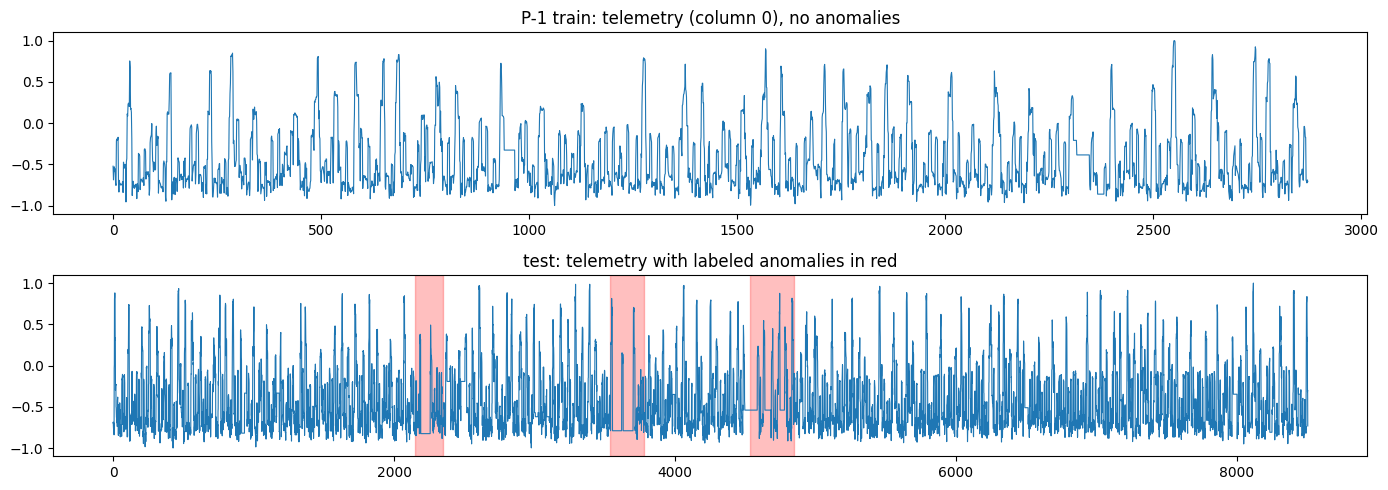

In [10]:
chan = chan_ids[0]
x_tr = np.load(train_dir/f"{chan}.npy"); x_te = np.load(test_dir/f"{chan}.npy")
print(chan, "| train", x_tr.shape, "| test", x_te.shape)   # (timesteps, 25) for SMAP, (timesteps, 55) for MSL
anoms = labels.loc[labels.chan_id == chan, "anomaly_sequences"].iloc[0]
print("labeled anomaly intervals (test indices):", anoms)

fig, ax = plt.subplots(2, 1, figsize=(14, 5))
ax[0].plot(x_tr[:, 0], lw=0.8); ax[0].set_title(f"{chan} train: telemetry (column 0), no anomalies")
ax[1].plot(x_te[:, 0], lw=0.8); ax[1].set_title("test: telemetry with labeled anomalies in red")
for s, e in anoms: ax[1].axvspan(s, e, color="red", alpha=0.25)
plt.tight_layout(); plt.show()

In [11]:
def fit_minmax(x):
    lo, hi = x.min(axis=0), x.max(axis=0)
    scale = np.where(hi - lo < 1e-8, 1.0, hi - lo)
    return lo.astype(np.float32), scale.astype(np.float32)

def apply_minmax(x, lo, scale):
    return ((x - lo) / scale).astype(np.float32)

def make_windows(x, w):
    X = x.unfold(0, w, 1)[:-1]     # (N, F, w) view; sample i = x[i:i+w]
    y = x[w:, 0]                   # target = next telemetry value
    return X, y

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

# quick check
lo, scale = fit_minmax(x_tr)
xs = torch.tensor(apply_minmax(x_tr, lo, scale))
X, y = make_windows(xs, CFG["window"])
print("scaled train range:", xs[:, 0].min().item(), xs[:, 0].max().item())
print("windows:", tuple(X.shape), "-> targets:", tuple(y.shape))   # (T-250, F, 250) and (T-250,)

scaled train range: 0.0 1.0
windows: (2622, 25, 250) -> targets: (2622,)


In [12]:
class LSTMPredictor(nn.Module):
    def __init__(self, n_features, hidden=80, layers=2, dropout=0.3):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden, num_layers=layers, batch_first=True,
                            dropout=dropout if layers > 1 else 0.0)
        self.head = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1]).squeeze(-1)

m = LSTMPredictor(x_tr.shape[1]).to(DEVICE)
print("parameters:", sum(p.numel() for p in m.parameters()))
print("output shape for a batch of 4:", m(torch.randn(4, 250, x_tr.shape[1], device=DEVICE)).shape)  # torch.Size([4])
del m

parameters: 86161
output shape for a batch of 4: torch.Size([4])


In [13]:
@torch.no_grad()
def mse_over(model, X, y, bs=512):
    model.eval(); total = 0.0
    for i in range(0, len(y), bs):
        total += ((model(X[i:i+bs].permute(0, 2, 1).contiguous()) - y[i:i+bs]) ** 2).sum().item()
    return total / len(y)

def train_channel(x_train_scaled, verbose=False):
    cfg, w = CFG, CFG["window"]
    set_seed(cfg["seed"])
    T, F = x_train_scaled.shape
    n_val = int(T * cfg["val_frac"])
    if T - n_val - w < 50 or n_val < 10: raise ValueError(f"training series too short (T={T})")
    x = torch.tensor(x_train_scaled, device=DEVICE)
    Xtr, ytr = make_windows(x[: T - n_val], w)          # chronological split
    Xva, yva = make_windows(x[T - n_val - w:], w)       # validation windows reuse w steps of context
    model = LSTMPredictor(F, cfg["hidden"], cfg["layers"], cfg["dropout"]).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"]); loss_fn = nn.MSELoss()
    gen = torch.Generator().manual_seed(cfg["seed"])
    best, best_state, bad, hist = float("inf"), None, 0, []
    for epoch in range(cfg["max_epochs"]):
        model.train()
        perm = torch.randperm(len(ytr), generator=gen).to(DEVICE)
        running = torch.zeros((), device=DEVICE)
        for i in range(0, len(perm), cfg["batch_size"]):
            idx = perm[i:i + cfg["batch_size"]]
            opt.zero_grad()
            loss = loss_fn(model(Xtr[idx].permute(0, 2, 1).contiguous()), ytr[idx])
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])
            opt.step()
            running += loss.detach() * len(idx)
        tr_loss, va_loss = running.item() / len(ytr), mse_over(model, Xva, yva)
        hist.append((tr_loss, va_loss))
        improved = va_loss < best - cfg["min_delta"]
        if improved:
            best, bad = va_loss, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        if verbose: print(f"epoch {epoch+1:2d} | train {tr_loss:.5f} | val {va_loss:.5f}" + (" *best" if improved else ""))
        if bad >= cfg["patience"]: break
    if best_state is not None: model.load_state_dict(best_state)
    else: best = hist[-1][1]
    return model, best, hist

@torch.no_grad()
def predict_series(model, x_scaled, bs=512):
    w = CFG["window"]
    model.eval()
    X, y = make_windows(torch.tensor(x_scaled, device=DEVICE), w)
    preds = [model(X[i:i+bs].permute(0, 2, 1).contiguous()).cpu() for i in range(0, len(y), bs)]
    return torch.cat(preds).numpy(), y.cpu().numpy()    # element i = test timestep i + window

def plot_result(chan, y_true, y_pred, err, off):
    t = np.arange(off, off + len(y_true))
    fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
    ax[0].plot(t, y_true, lw=0.8, label="true"); ax[0].plot(t, y_pred, lw=0.8, label="predicted")
    ax[0].set_title(f"{chan}: telemetry (scaled)"); ax[0].legend(loc="upper right")
    ax[1].plot(t, err, lw=0.8, color="tab:orange"); ax[1].set_title("absolute prediction error"); ax[1].set_xlabel("test timestep")
    for s, e in labels.loc[labels.chan_id == chan, "anomaly_sequences"].iloc[0]:
        for a in ax: a.axvspan(s, e, color="red", alpha=0.2)
    plt.tight_layout(); plt.show()
print("functions defined")

functions defined


epoch  1 | train 0.03489 | val 0.02758 *best
epoch  2 | train 0.02048 | val 0.01997 *best
epoch  3 | train 0.01662 | val 0.01688 *best
epoch  4 | train 0.01473 | val 0.01663
epoch  5 | train 0.01287 | val 0.01435 *best
epoch  6 | train 0.01226 | val 0.01341 *best
epoch  7 | train 0.01121 | val 0.01200 *best
epoch  8 | train 0.01065 | val 0.01164 *best
epoch  9 | train 0.01005 | val 0.01050 *best
epoch 10 | train 0.00944 | val 0.00936 *best
epoch 11 | train 0.00936 | val 0.00945
epoch 12 | train 0.00911 | val 0.00882 *best
epoch 13 | train 0.00865 | val 0.00811 *best
epoch 14 | train 0.00816 | val 0.00822
epoch 15 | train 0.00822 | val 0.00814
epoch 16 | train 0.00816 | val 0.00751 *best
epoch 17 | train 0.00788 | val 0.00764
epoch 18 | train 0.00794 | val 0.00743
epoch 19 | train 0.00792 | val 0.00764
epoch 20 | train 0.00805 | val 0.00802
epoch 21 | train 0.00773 | val 0.00719 *best
epoch 22 | train 0.00760 | val 0.00737
epoch 23 | train 0.00760 | val 0.00703
epoch 24 | train 0.00744 

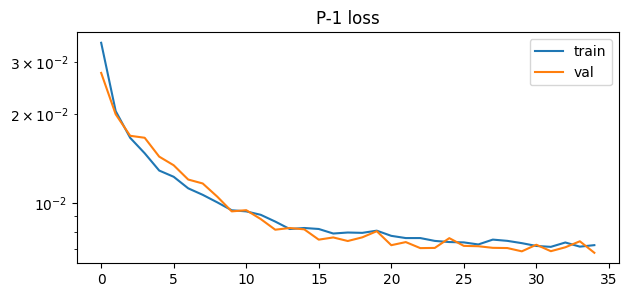

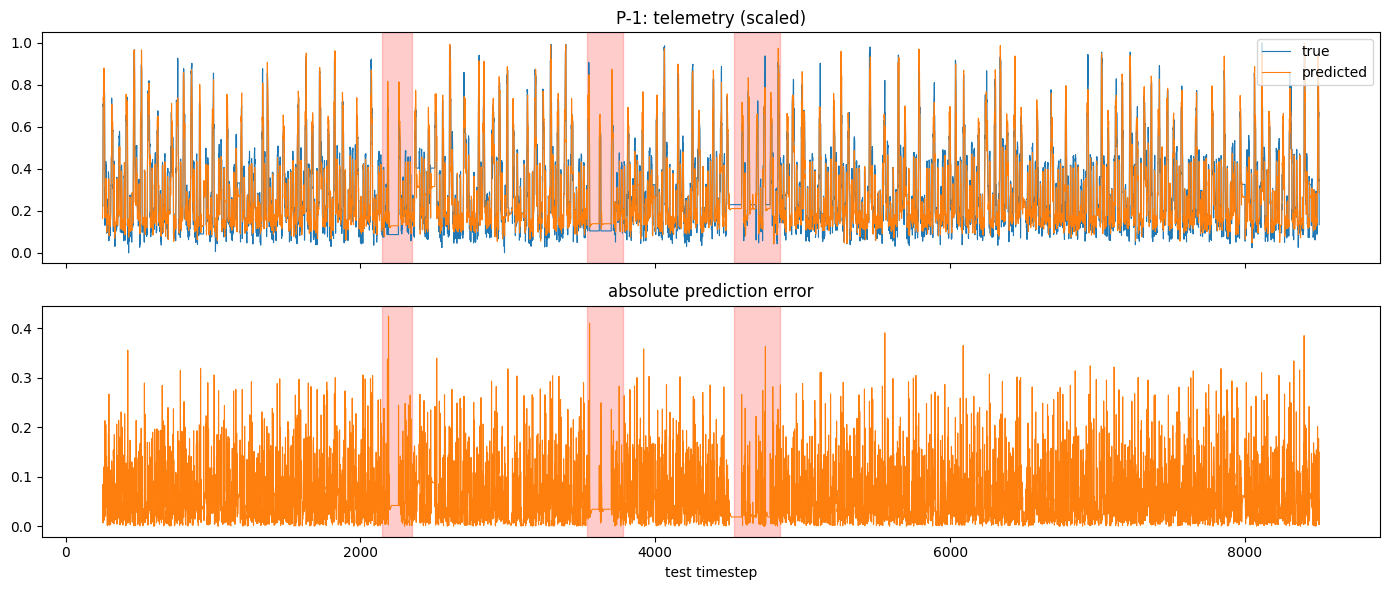

mean abs error: 0.05942381


In [14]:
chan = chan_ids[0]
x_tr = np.load(train_dir/f"{chan}.npy").astype(np.float32); x_te = np.load(test_dir/f"{chan}.npy").astype(np.float32)
lo, scale = fit_minmax(x_tr)
x_tr_s, x_te_s = apply_minmax(x_tr, lo, scale), apply_minmax(x_te, lo, scale)

t0 = time.time()
model, best_val, hist = train_channel(x_tr_s, verbose=True)
print(f"\ntrained in {time.time()-t0:.0f}s | best val MSE {best_val:.5f} | epochs {len(hist)}")

plt.figure(figsize=(7, 3))
plt.plot([h[0] for h in hist], label="train"); plt.plot([h[1] for h in hist], label="val")
plt.yscale("log"); plt.legend(); plt.title(f"{chan} loss"); plt.show()

preds, y_true = predict_series(model, x_te_s)
err = np.abs(y_true - preds)
plot_result(chan, y_true, preds, err, CFG["window"])
print("mean abs error:", err.mean())

In [15]:
def run_channel(chan):
    ckpt_path, pred_path = MODEL_DIR/f"{chan}.pt", PRED_DIR/f"{chan}.npz"
    if ckpt_path.exists() and pred_path.exists():
        tqdm.write(f"[{chan}] already done, skipping"); return None
    w = CFG["window"]
    x_tr = np.load(train_dir/f"{chan}.npy").astype(np.float32); x_te = np.load(test_dir/f"{chan}.npy").astype(np.float32)
    lo, scale = fit_minmax(x_tr)
    x_tr_s, x_te_s = apply_minmax(x_tr, lo, scale), apply_minmax(x_te, lo, scale)
    row = {"chan_id": chan, "n_train": len(x_tr), "n_test": len(x_te), "n_features": x_tr.shape[1]}
    if ckpt_path.exists():
        ck = torch.load(ckpt_path, map_location=DEVICE)
        model = LSTMPredictor(ck["n_features"], ck["cfg"]["hidden"], ck["cfg"]["layers"], ck["cfg"]["dropout"]).to(DEVICE)
        model.load_state_dict(ck["state_dict"])
        row.update(epochs=len(ck["history"]), best_val_mse=ck["best_val"], train_sec=0.0)
    else:
        t0 = time.time()
        model, best_val, hist = train_channel(x_tr_s)
        tmp = ckpt_path.with_name(ckpt_path.name + ".tmp")
        torch.save({"state_dict": {k: v.cpu() for k, v in model.state_dict().items()}, "cfg": dict(CFG),
                    "n_features": x_tr.shape[1], "scaler_lo": torch.from_numpy(lo), "scaler_scale": torch.from_numpy(scale),
                    "history": hist, "best_val": float(best_val)}, tmp)
        tmp.replace(ckpt_path)
        row.update(epochs=len(hist), best_val_mse=float(best_val), train_sec=round(time.time()-t0, 1))
    preds, y_true = predict_series(model, x_te_s)
    err = np.abs(y_true - preds)
    tmp = pred_path.with_name(pred_path.stem + ".tmp.npz")
    np.savez_compressed(tmp, y_true=y_true, y_pred=preds, err=err, offset=w)   # index i = test timestep i + offset
    tmp.replace(pred_path)
    row["test_mean_abs_err"] = float(err.mean())
    tqdm.write(f"[{chan}] epochs={row['epochs']} val_mse={row['best_val_mse']:.5f} test_mae={row['test_mean_abs_err']:.4f} time={row['train_sec']}s")
    return row

QUICK_TEST, QUICK_N = True, 3            # set QUICK_TEST = False to run all 82 channels
channels = chan_ids[:QUICK_N] if QUICK_TEST else chan_ids
log_path, failures = OUT_ROOT/"training_log.csv", []
for chan in tqdm(channels, desc="channels"):
    try:
        row = run_channel(chan)
        if row is not None:
            pd.DataFrame([row]).to_csv(log_path, mode="a", header=not log_path.exists(), index=False)
    except Exception as e:
        failures.append((chan, repr(e))); tqdm.write(f"[{chan}] FAILED: {e!r}")
print(f"\nDone: {len(channels)-len(failures)}/{len(channels)} OK", failures or "")

channels:   0%|          | 0/3 [00:00<?, ?it/s]

[P-1] epochs=35 val_mse=0.00685 test_mae=0.0594 time=6.6s
[S-1] epochs=35 val_mse=0.08207 test_mae=0.2334 time=6.2s
[E-1] epochs=33 val_mse=0.00083 test_mae=0.0447 time=6.0s

Done: 3/3 OK 


3 channels saved: ['E-1', 'P-1', 'S-1']


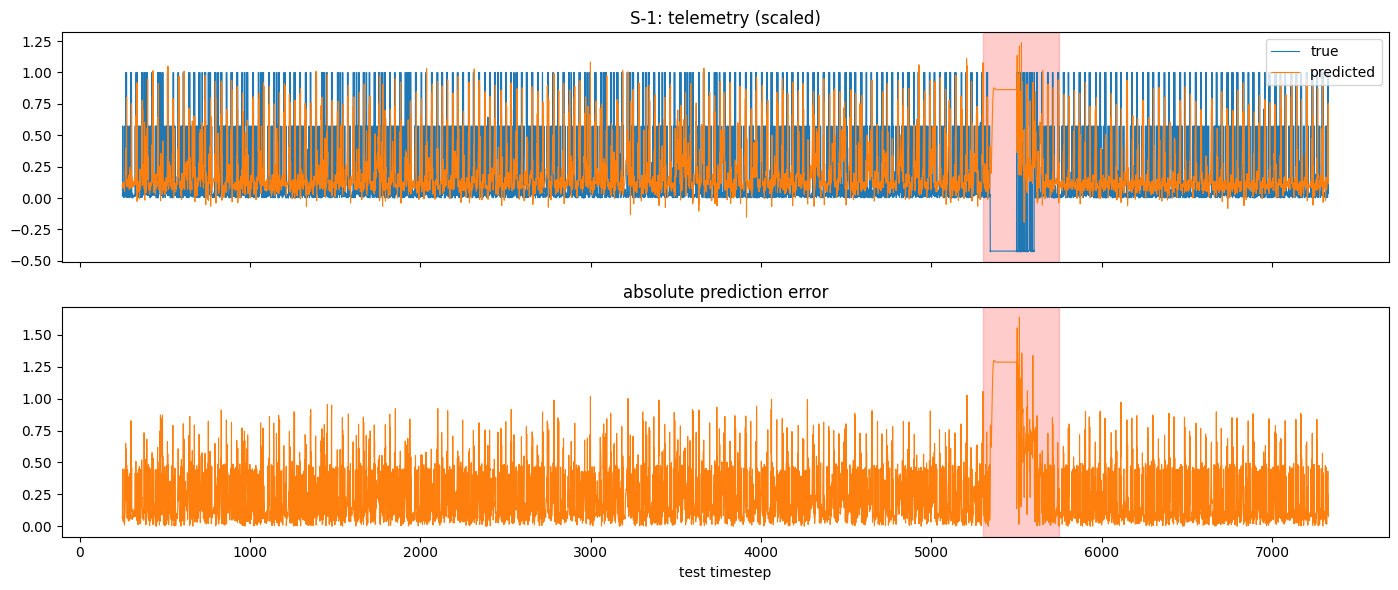

,chan_id,n_train,n_test,n_features,epochs,best_val_mse,train_sec,test_mean_abs_err
0,P-1,2872,8505,25,35,0.006854,6.6,0.059424
1,S-1,2818,7331,25,35,0.082070,6.2,0.233360
2,E-1,2880,8516,25,33,0.000828,6.0,0.044676


In [16]:
def plot_saved(chan):
    d = np.load(PRED_DIR/f"{chan}.npz")
    plot_result(chan, d["y_true"], d["y_pred"], d["err"], int(d["offset"]))

done = sorted(p.stem for p in PRED_DIR.glob("*.npz") if not p.stem.endswith(".tmp"))
print(len(done), "channels saved:", done[:10])
plot_saved(done[-1])
pd.read_csv(log_path).tail(10)

In [20]:
def ewma(x, span):
    return pd.Series(x).ewm(span=span, adjust=False).mean().to_numpy()

def groups(mask):
    """Boolean mask -> list of (start, end) runs of True (inclusive)."""
    idx = np.flatnonzero(mask)
    if len(idx) == 0: return []
    cuts = np.flatnonzero(np.diff(idx) > 1)
    starts, ends = np.r_[idx[0], idx[cuts + 1]], np.r_[idx[cuts], idx[-1]]
    return list(zip(starts.tolist(), ends.tolist()))

def merge_gaps(seqs, gap):
    out = []
    for s, e in seqs:
        if out and s - out[-1][1] <= gap: out[-1] = (out[-1][0], e)
        else: out.append((s, e))
    return out

def find_epsilon(e_s, z_range=np.arange(2.5, 30.0, 0.5), max_seqs=10, max_frac=0.5, robust=True):
    """Dynamic threshold (Telemanom-style): try centre + z*spread for many z and keep the one whose removal of
    flagged points most reduces the mean/std of the errors, penalising many alerts.
    robust=True uses median/MAD for the centre and spread, so long anomalies don't inflate the threshold."""
    mu, sd = e_s.mean(), e_s.std()                       # used for scoring
    if robust:
        centre = np.median(e_s)
        spread = 1.4826 * np.median(np.abs(e_s - centre))
        if spread <= 0: spread = sd if sd > 0 else 1e-8
    else:
        centre, spread = mu, sd
    best_score, best_eps = -np.inf, centre + spread * z_range[-1]
    for z in z_range:
        eps = centre + spread * z
        above = e_s > eps
        n_pts = int(above.sum())
        if n_pts == 0: continue
        seqs = [g for g in groups(above) if g[1] > g[0]]
        kept = e_s[~above]
        score = ((mu - kept.mean()) / mu + (sd - kept.std()) / sd) / (len(seqs) ** 2 + n_pts)
        if score >= best_score and len(seqs) <= max_seqs and n_pts < len(e_s) * max_frac:
            best_score, best_eps = score, eps
    return best_eps

def prune_sequences(e_s, seqs, normal_max, p=0.13):
    """Drop alerts whose peak error is not clearly above the next-highest peak (down to the largest normal error)."""
    if not seqs: return seqs
    maxes = np.array([e_s[s:e + 1].max() for s, e in seqs])
    order = np.argsort(-maxes)
    ranked = list(maxes[order]) + [normal_max]
    to_remove = []
    for i in range(len(seqs)):
        delta = (ranked[i] - ranked[i + 1]) / ranked[i]
        if delta < p: to_remove.append(i)
        else: to_remove = []
    drop = {int(order[i]) for i in to_remove}
    return [sq for j, sq in enumerate(seqs) if j not in drop]

def detect(err, offset, span=30, p=0.13, gap=20, min_len=2, **eps_kw):
    """err: raw prediction errors. Returns smoothed errors, threshold, alert sequences in TEST timestep indices."""
    e_s = ewma(err, span)
    eps = find_epsilon(e_s, **eps_kw)
    seqs = merge_gaps(groups(e_s > eps), gap)
    seqs = [s for s in seqs if s[1] - s[0] + 1 >= min_len]
    cover = np.zeros(len(e_s), bool)
    for s, e in seqs: cover[s:e + 1] = True
    normal_max = e_s[~cover].max() if (~cover).any() else 0.0
    seqs = prune_sequences(e_s, seqs, normal_max, p)
    return e_s, eps, [(s + offset, e + offset) for s, e in seqs]

def overlap(a, b): return a[0] <= b[1] and b[0] <= a[1]

def event_counts(true_seqs, pred_seqs):
    tp = sum(any(overlap(t, q) for q in pred_seqs) for t in true_seqs)      # labeled anomalies that were found
    fn = len(true_seqs) - tp                                                # labeled anomalies that were missed
    fp = sum(not any(overlap(q, t) for t in true_seqs) for q in pred_seqs)  # alerts matching no labeled anomaly
    return tp, fp, fn

def parse_classes(s):
    return [c.strip() for c in str(s).strip("[]").split(",")]

def evaluate(chans, **kw):
    rows, ivs = [], []
    for chan in chans:
        d = np.load(PRED_DIR / f"{chan}.npz")
        _, _, pred = detect(d["err"], int(d["offset"]), **kw)
        r = labels.loc[labels.chan_id == chan].iloc[0]
        true = [tuple(t) for t in r["anomaly_sequences"]]
        cls = parse_classes(r["class"])
        if len(cls) != len(true): cls = ["unknown"] * len(true)
        tp, fp, fn = event_counts(true, pred)
        rows.append(dict(chan_id=chan, spacecraft=r["spacecraft"], n_true=len(true), n_alerts=len(pred), tp=tp, fp=fp, fn=fn))
        ivs += [dict(spacecraft=r["spacecraft"], cls=c, found=any(overlap(t, q) for q in pred)) for t, c in zip(true, cls)]
    return pd.DataFrame(rows), pd.DataFrame(ivs)

def summarize(df):
    tp, fp, fn = int(df.tp.sum()), int(df.fp.sum()), int(df.fn.sum())
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return dict(TP=tp, FP=fp, FN=fn, precision=round(prec, 3), recall=round(rec, 3), F1=round(f1, 3))

def plot_detection(chan, **kw):
    d = np.load(PRED_DIR / f"{chan}.npz"); off = int(d["offset"])
    e_s, eps, pred = detect(d["err"], off, **kw)
    t = np.arange(off, off + len(e_s))
    fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
    ax[0].plot(t, d["y_true"], lw=0.8, label="true"); ax[0].plot(t, d["y_pred"], lw=0.8, label="predicted")
    ax[0].legend(loc="upper right"); ax[0].set_title(f"{chan}: telemetry")
    ax[1].plot(t, e_s, lw=0.8, color="tab:orange"); ax[1].axhline(eps, color="k", ls="--", lw=1, label="threshold")
    ax[1].set_title("smoothed error | red = labeled anomaly, blue = detected alert"); ax[1].legend(loc="upper right")
    for s, e in labels.loc[labels.chan_id == chan, "anomaly_sequences"].iloc[0]:
        for a in ax: a.axvspan(s, e, color="red", alpha=0.2)
    for s, e in pred:
        for a in ax: a.axvspan(s, e + 1, ymax=0.08, color="tab:blue", alpha=0.9)
    plt.tight_layout(); plt.show()
    print("alerts:", pred, "| labeled:", [tuple(x) for x in labels.loc[labels.chan_id == chan, "anomaly_sequences"].iloc[0]])
print("detection functions defined")

detection functions defined


In [21]:
done = sorted(p.stem for p in PRED_DIR.glob("*.npz") if not p.stem.endswith(".tmp"))
print(len(done), "channels with saved predictions\n")

res, iv = evaluate(done, span=30, robust=True)          # default settings
print(res.to_string(index=False))
print("\nOVERALL     :", summarize(res))
for sc, g in res.groupby("spacecraft"): print(f"{sc:<12}:", summarize(g))
print("\nlabeled anomalies found, by class:")
print(iv.groupby("cls")["found"].agg(found="sum", total="count").to_string())

res_plain, _ = evaluate(done, span=30, robust=False)    # same pipeline, plain mean/std threshold
print("\nthreshold comparison (same predictions):")
print("  robust (median/MAD):", summarize(res))
print("  plain  (mean/std)  :", summarize(res_plain))

3 channels with saved predictions

chan_id spacecraft  n_true  n_alerts  tp  fp  fn
    E-1       SMAP       2         0   0   0   2
    P-1       SMAP       3         0   0   0   3
    S-1       SMAP       1         1   1   0   0

OVERALL     : {'TP': 1, 'FP': 0, 'FN': 5, 'precision': 1.0, 'recall': 0.167, 'F1': 0.286}
SMAP        : {'TP': 1, 'FP': 0, 'FN': 5, 'precision': 1.0, 'recall': 0.167, 'F1': 0.286}

labeled anomalies found, by class:
            found  total
cls                     
contextual      0      5
point           1      1

threshold comparison (same predictions):
  robust (median/MAD): {'TP': 1, 'FP': 0, 'FN': 5, 'precision': 1.0, 'recall': 0.167, 'F1': 0.286}
  plain  (mean/std)  : {'TP': 1, 'FP': 0, 'FN': 5, 'precision': 1.0, 'recall': 0.167, 'F1': 0.286}


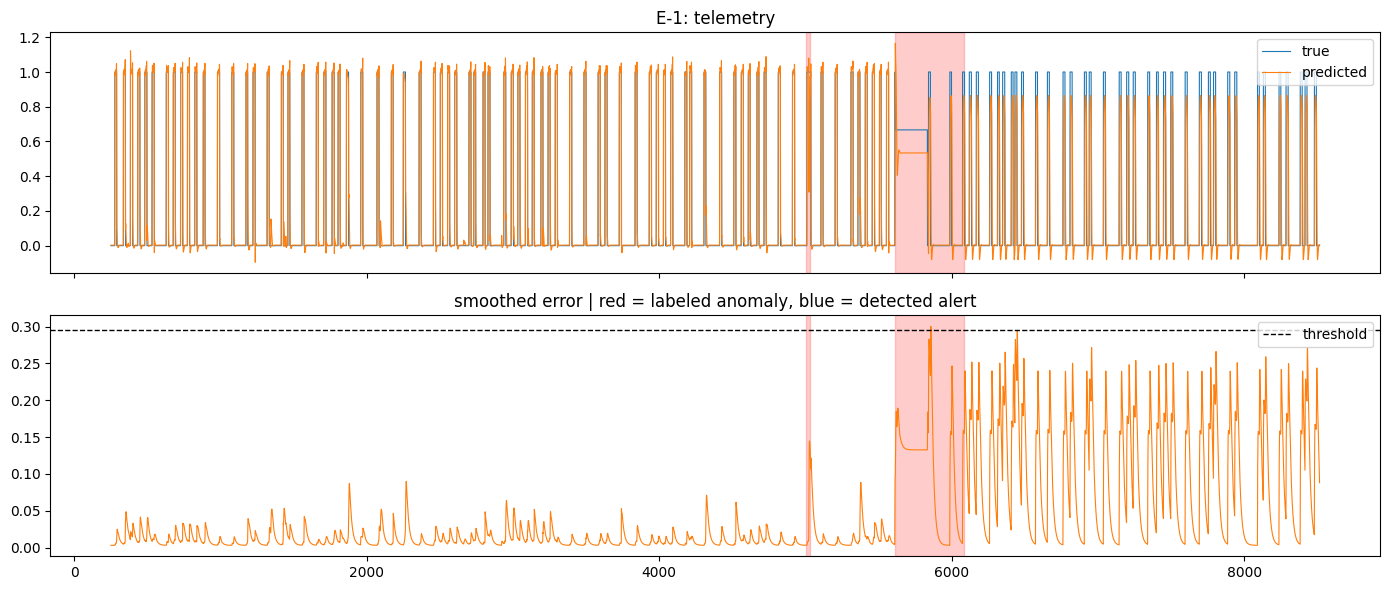

alerts: [] | labeled: [(5000, 5030), (5610, 6086)]


In [22]:
plot_detection(done[0], span=30)

In [23]:
def signal_check(chans, span=30, robust=True):
    """For every labeled anomaly: how high does the smoothed error get inside it, compared with the threshold
    and with the error during normal operation? (Diagnosis only: it uses the labels.)"""
    rows = []
    for chan in chans:
        d = np.load(PRED_DIR / f"{chan}.npz"); off = int(d["offset"])
        e_s, eps, _ = detect(d["err"], off, span=span, robust=robust)
        ivs = [tuple(t) for t in labels.loc[labels.chan_id == chan, "anomaly_sequences"].iloc[0]]
        inside = np.zeros(len(e_s), bool)
        for s, e in ivs:
            inside[max(s - off, 0):max(e - off + 1, 0)] = True
        normal_p99 = np.percentile(e_s[~inside], 99)
        for s, e in ivs:
            a, b = max(s - off, 0), min(e - off + 1, len(e_s))
            if b <= a:
                rows.append(dict(chan_id=chan, interval=(s, e), note="before first prediction")); continue
            pk = e_s[a:b].max()
            rows.append(dict(chan_id=chan, interval=(s, e), length=e - s + 1, peak_inside=round(pk, 4),
                             threshold=round(eps, 4), normal_p99=round(normal_p99, 4),
                             peak_vs_threshold=round(pk / eps, 2), peak_vs_normal_p99=round(pk / normal_p99, 2)))
    return pd.DataFrame(rows)

signal_check(done)

,chan_id,interval,length,peak_inside,threshold,normal_p99,peak_vs_threshold,peak_vs_normal_p99
0,E-1,"(5000, 5030)",31,0.1448,0.2959,0.2401,0.49,0.60
1,E-1,"(5610, 6086)",477,0.3004,0.2959,0.2401,1.02,1.25
2,P-1,"(2149, 2349)",201,0.1053,0.0994,0.0861,1.06,1.22
3,P-1,"(4536, 4844)",309,0.0742,0.0994,0.0861,0.75,0.86
4,P-1,"(3539, 3779)",241,0.0793,0.0994,0.0861,0.80,0.92
5,S-1,"(5300, 5747)",448,1.2862,1.0778,0.3176,1.19,4.05


In [24]:
for p in (0.13, 0.0):
    res, _ = evaluate(done, span=30, robust=True, p=p)
    print(f"p={p}:", summarize(res), "| alerts per channel:", res.n_alerts.tolist())

p=0.13: {'TP': 1, 'FP': 0, 'FN': 5, 'precision': 1.0, 'recall': 0.167, 'F1': 0.286} | alerts per channel: [0, 0, 1]
p=0.0: {'TP': 2, 'FP': 0, 'FN': 4, 'precision': 1.0, 'recall': 0.333, 'F1': 0.5} | alerts per channel: [0, 1, 1]


In [25]:
done = sorted(p.stem for p in PRED_DIR.glob("*.npz") if not p.stem.endswith(".tmp"))
print(len(done), "channels evaluated\n")

for p in (0.13, 0.0):   # 0.13 = main result, 0.0 = sensitivity check (no pruning)
    res, _ = evaluate(done, span=30, robust=True, p=p)
    print(f"p={p} OVERALL:", summarize(res))
    for sc, g in res.groupby("spacecraft"):
        print(f"   {sc:<5}:", summarize(g))
    print()

3 channels evaluated

p=0.13 OVERALL: {'TP': 1, 'FP': 0, 'FN': 5, 'precision': 1.0, 'recall': 0.167, 'F1': 0.286}
   SMAP : {'TP': 1, 'FP': 0, 'FN': 5, 'precision': 1.0, 'recall': 0.167, 'F1': 0.286}

p=0.0 OVERALL: {'TP': 2, 'FP': 0, 'FN': 4, 'precision': 1.0, 'recall': 0.333, 'F1': 0.5}
   SMAP : {'TP': 2, 'FP': 0, 'FN': 4, 'precision': 1.0, 'recall': 0.333, 'F1': 0.5}



In [26]:
def run_channel(chan):
    ckpt_path, pred_path = MODEL_DIR/f"{chan}.pt", PRED_DIR/f"{chan}.npz"
    if ckpt_path.exists() and pred_path.exists():
        return None                                   # already finished in an earlier run
    w = CFG["window"]
    x_tr = np.load(train_dir/f"{chan}.npy").astype(np.float32); x_te = np.load(test_dir/f"{chan}.npy").astype(np.float32)
    lo, scale = fit_minmax(x_tr)
    x_tr_s, x_te_s = apply_minmax(x_tr, lo, scale), apply_minmax(x_te, lo, scale)
    row = {"chan_id": chan, "n_train": len(x_tr), "n_test": len(x_te), "n_features": x_tr.shape[1]}
    if ckpt_path.exists():                            # model saved but predictions missing
        ck = torch.load(ckpt_path, map_location=DEVICE)
        model = LSTMPredictor(ck["n_features"], ck["cfg"]["hidden"], ck["cfg"]["layers"], ck["cfg"]["dropout"]).to(DEVICE)
        model.load_state_dict(ck["state_dict"])
        row.update(epochs=len(ck["history"]), best_val_mse=ck["best_val"], train_sec=0.0)
    else:
        t0 = time.time()
        model, best_val, hist = train_channel(x_tr_s)
        tmp = ckpt_path.with_name(ckpt_path.name + ".tmp")
        torch.save({"state_dict": {k: v.cpu() for k, v in model.state_dict().items()}, "cfg": dict(CFG),
                    "n_features": x_tr.shape[1], "scaler_lo": torch.from_numpy(lo), "scaler_scale": torch.from_numpy(scale),
                    "history": hist, "best_val": float(best_val)}, tmp)
        tmp.replace(ckpt_path)                        # atomic: never a half-written model
        row.update(epochs=len(hist), best_val_mse=float(best_val), train_sec=round(time.time()-t0, 1))
    preds, y_true = predict_series(model, x_te_s)
    err = np.abs(y_true - preds)
    tmp = pred_path.with_name(pred_path.stem + ".tmp.npz")
    np.savez_compressed(tmp, y_true=y_true, y_pred=preds, err=err, offset=w)   # index i = test timestep i + offset
    tmp.replace(pred_path)
    row["test_mean_abs_err"] = float(err.mean())
    return row

log_path, failures = OUT_ROOT/"training_log.csv", []
todo = [c for c in chan_ids if not ((MODEL_DIR/f"{c}.pt").exists() and (PRED_DIR/f"{c}.npz").exists())]
print(f"{len(chan_ids)} channels total | {len(chan_ids)-len(todo)} already done | {len(todo)} to train")

for chan in tqdm(chan_ids, desc="channels"):
    try:
        row = run_channel(chan)
        if row is not None:
            pd.DataFrame([row]).to_csv(log_path, mode="a", header=not log_path.exists(), index=False)
            tqdm.write(f"[{chan}] epochs={row['epochs']} val_mse={row['best_val_mse']:.5f} "
                       f"test_mae={row['test_mean_abs_err']:.4f} time={row['train_sec']}s")
    except Exception as e:
        failures.append((chan, repr(e))); tqdm.write(f"[{chan}] FAILED: {e!r}")

print(f"\nDone: {len(chan_ids)-len(failures)}/{len(chan_ids)} OK")
if failures: print("Failures:", failures)

82 channels total | 3 already done | 79 to train


channels:   0%|          | 0/82 [00:00<?, ?it/s]

[E-2] epochs=28 val_mse=0.00109 test_mae=0.0523 time=7.9s
[E-3] epochs=21 val_mse=0.00059 test_mae=0.0395 time=3.9s
[E-4] epochs=16 val_mse=0.00065 test_mae=0.0764 time=3.0s
[E-5] epochs=35 val_mse=0.00040 test_mae=0.0783 time=6.5s
[E-6] epochs=27 val_mse=0.00149 test_mae=0.4489 time=5.1s
[E-7] epochs=33 val_mse=0.02632 test_mae=0.1909 time=6.0s
[E-8] epochs=17 val_mse=0.00096 test_mae=0.0685 time=3.2s
[E-9] epochs=13 val_mse=0.00137 test_mae=0.0691 time=2.5s
[E-10] epochs=35 val_mse=0.00029 test_mae=0.0493 time=6.7s
[E-11] epochs=35 val_mse=0.00043 test_mae=0.0471 time=7.2s
[E-12] epochs=30 val_mse=0.00044 test_mae=0.0451 time=5.8s
[E-13] epochs=35 val_mse=0.00425 test_mae=0.0335 time=6.7s
[A-1] epochs=11 val_mse=0.00004 test_mae=0.0079 time=2.1s
[D-1] epochs=35 val_mse=0.00604 test_mae=0.6078 time=6.7s
[P-2] epochs=20 val_mse=0.01768 test_mae=0.5919 time=3.8s
[P-3] epochs=20 val_mse=0.00215 test_mae=0.0264 time=3.9s
[D-2] epochs=11 val_mse=0.00005 test_mae=0.9245 time=2.1s
[D-3] epoc

In [27]:
print(len(list(PRED_DIR.glob("*.npz"))), "prediction files |", len(list(MODEL_DIR.glob("*.pt"))), "model files")
pd.read_csv(log_path).describe()

80 prediction files | 80 model files


,n_train,n_test,n_features,epochs,best_val_mse,train_sec,test_mean_abs_err
count,80.00000,80.000000,80.000000,80.00000,80.000000,80.000000,80.000000
mean,2450.11250,6270.462500,35.125000,21.98750,0.006922,3.863750,39.366453
std,776.32094,2720.563019,14.275211,9.89629,0.014538,2.318568,237.590779
min,439.00000,1096.000000,25.000000,11.00000,0.000002,0.400000,0.006630
25%,2208.75000,2798.250000,25.000000,12.00000,0.000278,2.000000,0.029917
50%,2713.00000,7879.000000,25.000000,19.50000,0.001120,3.450000,0.052084
75%,2880.00000,8478.000000,55.000000,35.00000,0.006399,5.725000,0.185825
max,4308.00000,8640.000000,55.000000,35.00000,0.082070,10.800000,1995.145508


In [28]:
done = sorted(p.stem for p in PRED_DIR.glob("*.npz") if not p.stem.endswith(".tmp"))
print(len(done), "channels evaluated\n")

res, iv = evaluate(done, span=30, robust=True, p=0.13)     # main result
print("OVERALL:", summarize(res))
for sc, g in res.groupby("spacecraft"):
    print(f"  {sc:<5}:", summarize(g))
print("\nlabeled anomalies found, by class:")
print(iv.groupby("cls")["found"].agg(found="sum", total="count").to_string())

80 channels evaluated

OVERALL: {'TP': 39, 'FP': 30, 'FN': 64, 'precision': 0.565, 'recall': 0.379, 'F1': 0.453}
  MSL  : {'TP': 12, 'FP': 1, 'FN': 24, 'precision': 0.923, 'recall': 0.333, 'F1': 0.49}
  SMAP : {'TP': 27, 'FP': 29, 'FN': 40, 'precision': 0.482, 'recall': 0.403, 'F1': 0.439}

labeled anomalies found, by class:
            found  total
cls                     
contextual      7     43
point          32     60


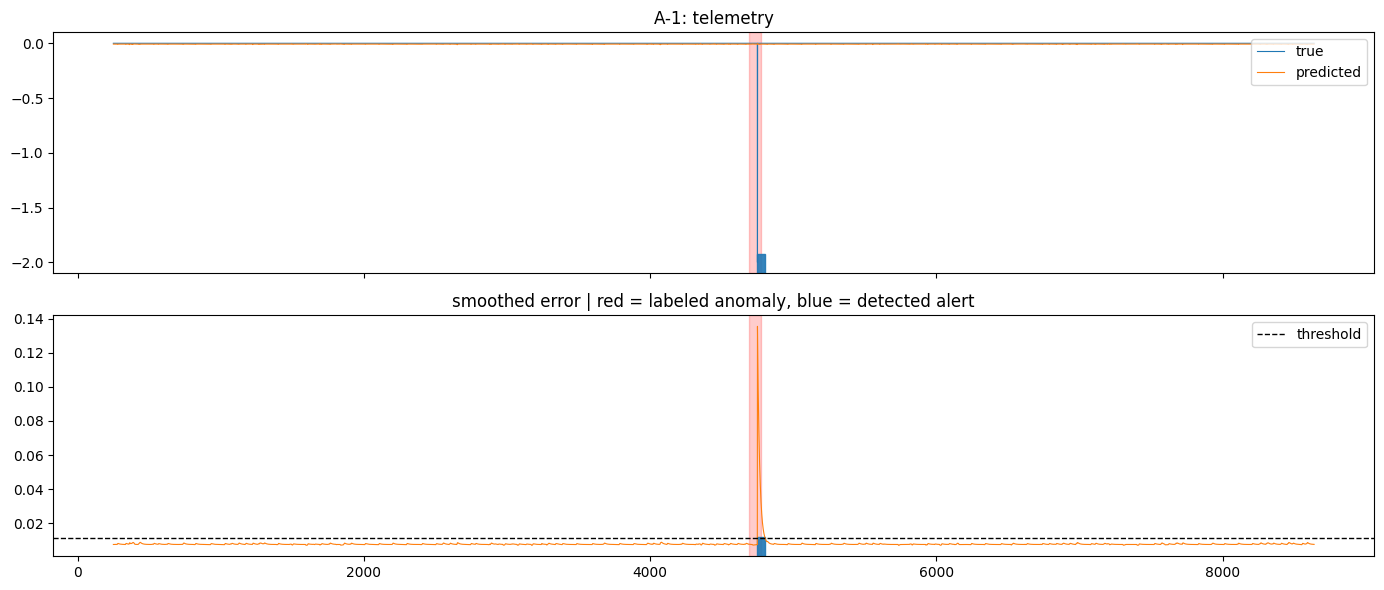

alerts: [(4750, 4802)] | labeled: [(4690, 4774)]


In [30]:
plot_detection(done[0], span=30, p=0.13)

In [31]:
signal_check(done).to_string(index=False)

'chan_id     interval  length  peak_inside  threshold  normal_p99  peak_vs_threshold  peak_vs_normal_p99\n    A-1 (4690, 4774)      85       0.1355     0.0115      0.0086              11.74               15.78\n    A-2 (4450, 4560)     111       0.1237     0.1181      0.1019               1.05                1.21\n    A-3 (4575, 4760)     186       0.1770     0.1763      0.0768               1.00                2.31\n    A-4 (4550, 4660)     111       0.1430     0.1426      0.0741               1.00                1.93\n    A-5 (2750, 2800)      51    1553.4938     0.6234   1491.4230            2491.80                1.04\n    A-6 (1890, 1930)      41       0.7234     0.2728      0.4010               2.65                1.80\n    A-7 (6200, 8600)    2401       0.1061     0.1013      0.0692               1.05                1.53\n    A-8 (4569, 8374)    3806       0.1969     0.1957      0.1698               1.01                1.16\n    A-9 (4569, 8433)    3865       0.1119     0.2383  

In [32]:
for p in (0.13, 0.0):
    res_p, _ = evaluate(done, span=30, robust=True, p=p)
    print(f"p={p} OVERALL:", summarize(res_p))
    for sc, g in res_p.groupby("spacecraft"):
        print(f"   {sc:<5}:", summarize(g))
    print()

p=0.13 OVERALL: {'TP': 39, 'FP': 30, 'FN': 64, 'precision': 0.565, 'recall': 0.379, 'F1': 0.453}
   MSL  : {'TP': 12, 'FP': 1, 'FN': 24, 'precision': 0.923, 'recall': 0.333, 'F1': 0.49}
   SMAP : {'TP': 27, 'FP': 29, 'FN': 40, 'precision': 0.482, 'recall': 0.403, 'F1': 0.439}

p=0.0 OVERALL: {'TP': 53, 'FP': 49, 'FN': 50, 'precision': 0.52, 'recall': 0.515, 'F1': 0.517}
   MSL  : {'TP': 17, 'FP': 10, 'FN': 19, 'precision': 0.63, 'recall': 0.472, 'F1': 0.54}
   SMAP : {'TP': 36, 'FP': 39, 'FN': 31, 'precision': 0.48, 'recall': 0.537, 'F1': 0.507}



best: G-7 | worst: P-1


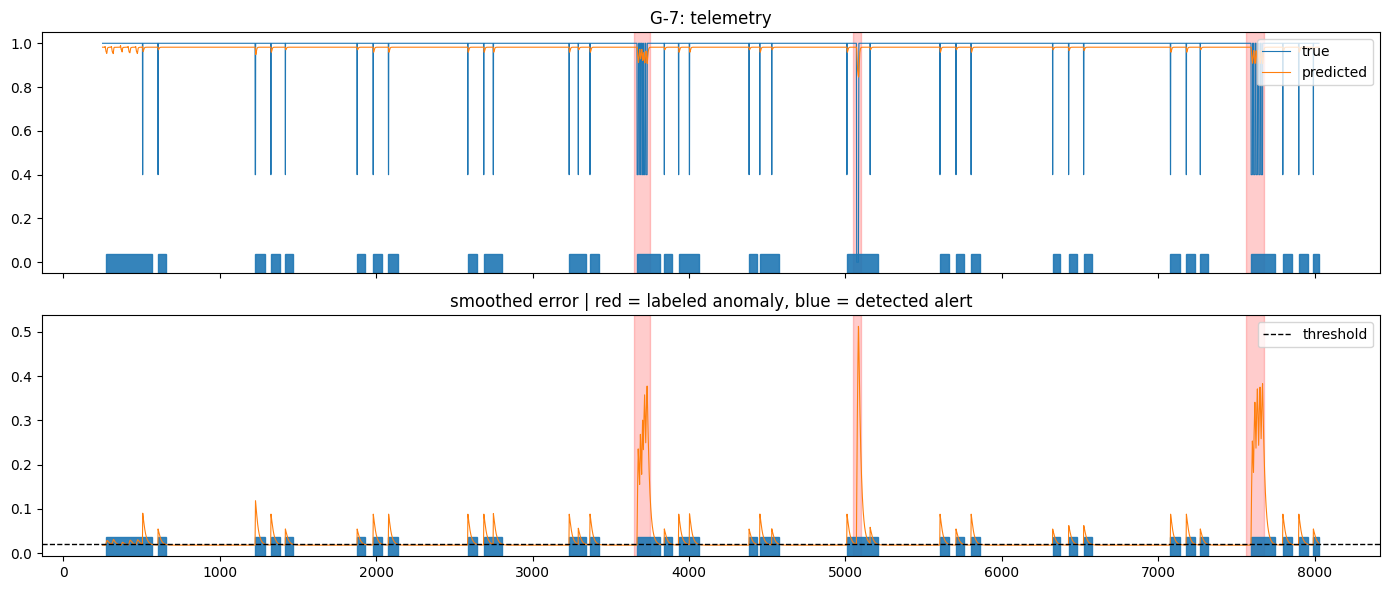

alerts: [(271, 564), (605, 652), (1226, 1290), (1326, 1384), (1419, 1466), (1878, 1925), (1980, 2038), (2078, 2136), (2585, 2643), (2687, 2806), (3233, 3340), (3366, 3424), (3668, 3812), (3842, 3889), (3933, 4060), (4384, 4431), (4452, 4577), (5009, 5207), (5604, 5662), (5707, 5754), (5803, 5861), (6325, 6372), (6427, 6478), (6523, 6574), (7078, 7136), (7179, 7237), (7269, 7316), (7594, 7747), (7796, 7854), (7898, 7956), (7992, 8028)] | labeled: [(3650, 3750), (5050, 5100), (7560, 7675)]


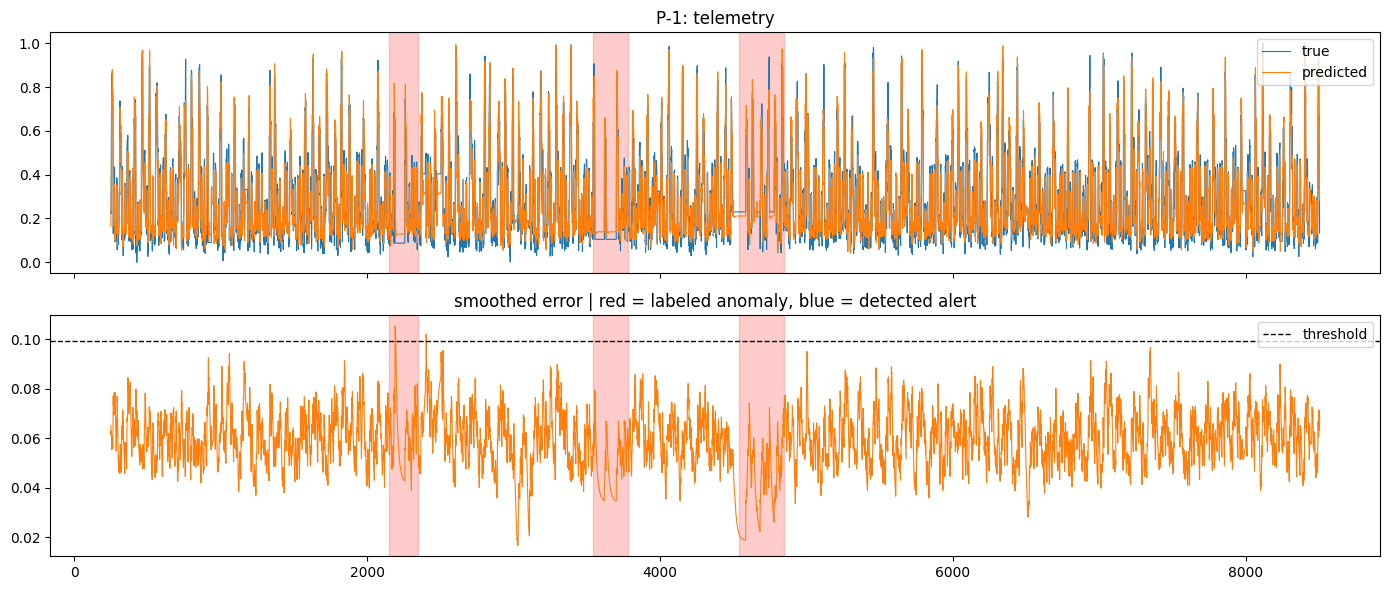

alerts: [] | labeled: [(2149, 2349), (4536, 4844), (3539, 3779)]


In [33]:
res, _ = evaluate(done, span=30, robust=True, p=0.13)
best = res.sort_values("tp", ascending=False).chan_id.iloc[0]
worst = res.sort_values("fn", ascending=False).chan_id.iloc[0]
print("best:", best, "| worst:", worst)
plot_detection(best); plot_detection(worst)

In [34]:
missing = sorted(set(chan_ids) - set(done))
print("missing:", missing)
print(failures)

missing: ['D-12']
[('D-12', "ValueError('training series too short (T=312)')")]


In [35]:
res, _ = evaluate(done, span=30, robust=True, p=0.13)
print(res.sort_values("fp", ascending=False).head(10).to_string(index=False))

chan_id spacecraft  n_true  n_alerts  tp  fp  fn
    G-7       SMAP       3        31   3  28   0
    T-8        MSL       2         3   2   1   0
    T-2       SMAP       1         1   0   1   1
    A-1       SMAP       1         1   1   0   0
    A-5       SMAP       1         1   1   0   0
    A-2       SMAP       1         0   0   0   1
    A-3       SMAP       1         0   0   0   1
    A-4       SMAP       1         0   0   0   1
    A-9       SMAP       1         0   0   0   1
    B-1       SMAP       1         0   0   0   1


In [36]:
rows = []
for c in chan_ids:
    tr = np.load(train_dir/f"{c}.npy"); te = np.load(test_dir/f"{c}.npy")
    rows.append((c, round(((te < tr.min(0)) | (te > tr.max(0))).any(1).mean(), 3)))
print(pd.DataFrame(rows, columns=["chan_id", "frac_test_out_of_train_range"])
        .sort_values("frac_test_out_of_train_range", ascending=False).head(10).to_string(index=False))

chan_id  frac_test_out_of_train_range
    A-1                         1.000
    R-1                         1.000
   D-12                         1.000
   P-14                         1.000
    D-5                         0.999
    C-2                         0.773
   P-15                         0.512
    M-6                         0.509
    D-2                         0.443
    D-3                         0.420


In [37]:
print("labels:", len(labels), "| usable:", len(chan_ids))
print("in labels but no files:", sorted(set(labels.chan_id) - set(chan_ids)))


labels: 82 | usable: 82
in labels but no files: []


In [38]:
rows = []
for c in chan_ids:
    tr = np.load(train_dir/f"{c}.npy"); te = np.load(test_dir/f"{c}.npy")
    tel_out = ((te[:, 0] < tr[:, 0].min()) | (te[:, 0] > tr[:, 0].max())).mean()
    cmd_out = ((te[:, 1:] < tr[:, 1:].min(0)) | (te[:, 1:] > tr[:, 1:].max(0))).any(1).mean()
    rows.append((c, round(tel_out, 3), round(cmd_out, 3)))
df = pd.DataFrame(rows, columns=["chan_id", "telemetry_out_of_range", "command_out_of_range"])
print(df.sort_values("telemetry_out_of_range", ascending=False).head(10).to_string(index=False))


chan_id  telemetry_out_of_range  command_out_of_range
    A-1                   1.000                 0.000
    R-1                   1.000                 0.000
   D-12                   1.000                 0.014
   P-14                   1.000                 0.013
    D-5                   0.999                 0.001
    C-2                   0.772                 0.012
   P-15                   0.511                 0.001
    M-6                   0.507                 0.004
    D-2                   0.443                 0.000
    D-3                   0.419                 0.000


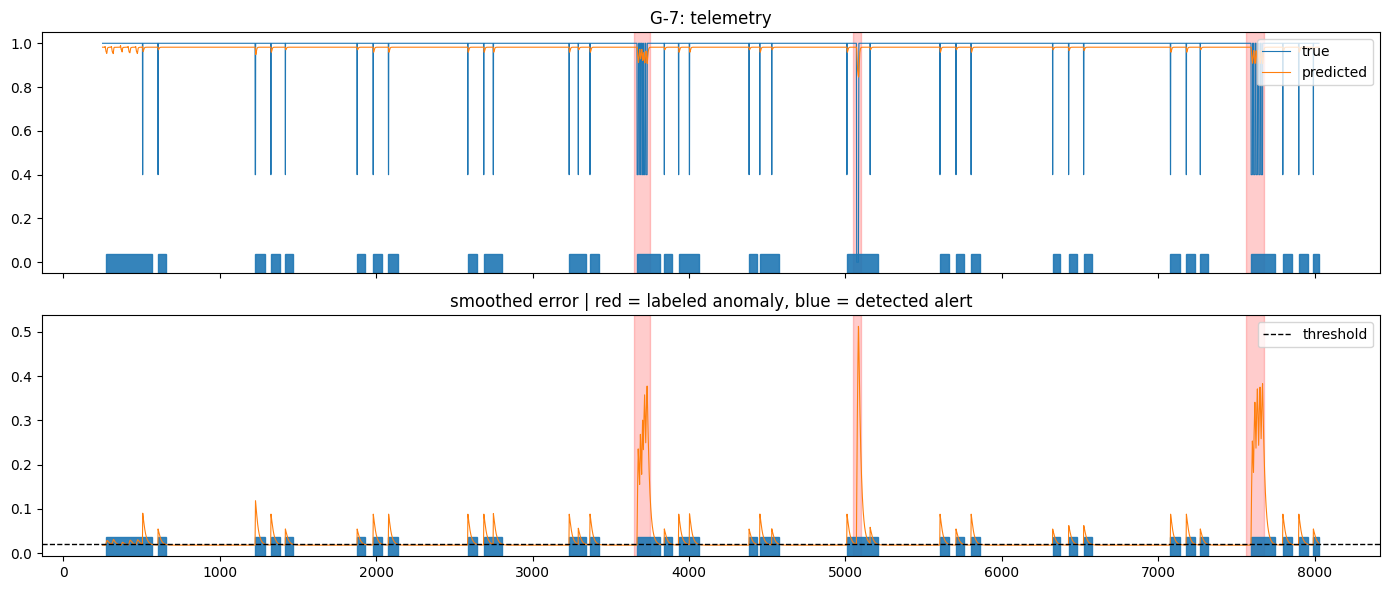

alerts: [(271, 564), (605, 652), (1226, 1290), (1326, 1384), (1419, 1466), (1878, 1925), (1980, 2038), (2078, 2136), (2585, 2643), (2687, 2806), (3233, 3340), (3366, 3424), (3668, 3812), (3842, 3889), (3933, 4060), (4384, 4431), (4452, 4577), (5009, 5207), (5604, 5662), (5707, 5754), (5803, 5861), (6325, 6372), (6427, 6478), (6523, 6574), (7078, 7136), (7179, 7237), (7269, 7316), (7594, 7747), (7796, 7854), (7898, 7956), (7992, 8028)] | labeled: [(3650, 3750), (5050, 5100), (7560, 7675)]


In [39]:
plot_detection("G-7", span=30, p=0.13)

In [40]:
CLIP_LO, CLIP_HI = -0.5, 1.5   # applied to SCALED test data, decided before looking at results

In [41]:
x_te_s = np.clip(apply_minmax(x_te, lo, scale), CLIP_LO, CLIP_HI)

In [45]:
CLIP_LO, CLIP_HI = -0.5, 1.5
PRED_CLIP_DIR = OUT_ROOT/"predictions_clip"
PRED_CLIP_DIR.mkdir(parents=True, exist_ok=True)
w = CFG["window"]

done_clip, failed = [], []
for chan in tqdm(chan_ids, desc="re-predicting"):
    out = PRED_CLIP_DIR/f"{chan}.npz"
    ckpt = MODEL_DIR/f"{chan}.pt"
    if out.exists() or not ckpt.exists():
        continue
    try:
        ck = torch.load(ckpt, map_location="cpu")              # load everything to CPU first
        lo = ck["scaler_lo"].cpu().numpy()
        scale = ck["scaler_scale"].cpu().numpy()

        model = LSTMPredictor(ck["n_features"], ck["cfg"]["hidden"], ck["cfg"]["layers"], ck["cfg"]["dropout"])
        model.load_state_dict(ck["state_dict"])
        model = model.to(DEVICE).eval()

        x_te = np.load(test_dir/f"{chan}.npy").astype(np.float32)
        x_te_s = apply_minmax(x_te, lo, scale)                  # numpy, CPU
        y_true = x_te_s[w:, 0]                                  # unclipped target
        preds, _ = predict_series(model, np.clip(x_te_s, CLIP_LO, CLIP_HI))

        err = np.abs(y_true - preds)
        tmp = out.with_name(out.stem + ".tmp.npz")
        np.savez_compressed(tmp, y_true=np.asarray(y_true), y_pred=np.asarray(preds),
                            err=np.asarray(err), offset=w)
        tmp.replace(out)
        done_clip.append(chan)
    except Exception as e:
        failed.append((chan, repr(e)))
        tqdm.write(f"[{chan}] FAILED: {e!r}")

print(f"Re-predicted {len(done_clip)} channels into {PRED_CLIP_DIR}")
if failed: print("Failures:", failed[:5], "...")

re-predicting:   0%|          | 0/82 [00:00<?, ?it/s]

Re-predicted 80 channels into /content/drive/MyDrive/anomaly/outputs/predictions_clip


In [46]:
ck = torch.load(MODEL_DIR/"P-1.pt", map_location="cpu"); print(ck["scaler_lo"].device, type(ck["scaler_lo"]))


cpu <class 'torch.Tensor'>


In [47]:
def eval_folder(folder):
    global PRED_DIR
    PRED_DIR = folder
    chans = sorted(p.stem for p in folder.glob("*.npz") if not p.stem.endswith(".tmp"))
    res, _ = evaluate(chans, span=30, robust=True, p=0.13)
    PRED_DIR = PRED_ORIG
    return len(chans), res

PRED_ORIG = OUT_ROOT/"predictions"
n_old, res_old = eval_folder(PRED_ORIG)
n_new, res_new = eval_folder(PRED_CLIP_DIR)
print(f"original (unclipped), {n_old} channels:", summarize(res_old))
print(f"clipped  [{CLIP_LO}, {CLIP_HI}], {n_new} channels:", summarize(res_new))
for sc in ["SMAP", "MSL"]:
    print(f"  {sc:<5} original:", summarize(res_old[res_old.spacecraft == sc]))
    print(f"  {sc:<5} clipped :", summarize(res_new[res_new.spacecraft == sc]))

both = res_old.merge(res_new, on=["chan_id", "spacecraft"], suffixes=("_old", "_new"))
both["fp_change"] = both.fp_new - both.fp_old
print("\nchannels with the largest change in false positives:")
print(both.reindex(both.fp_change.abs().sort_values(ascending=False).index)
          [["chan_id", "spacecraft", "tp_old", "tp_new", "fp_old", "fp_new"]].head(12).to_string(index=False))

original (unclipped), 80 channels: {'TP': 39, 'FP': 30, 'FN': 64, 'precision': 0.565, 'recall': 0.379, 'F1': 0.453}
clipped  [-0.5, 1.5], 80 channels: {'TP': 39, 'FP': 30, 'FN': 64, 'precision': 0.565, 'recall': 0.379, 'F1': 0.453}
  SMAP  original: {'TP': 27, 'FP': 29, 'FN': 40, 'precision': 0.482, 'recall': 0.403, 'F1': 0.439}
  SMAP  clipped : {'TP': 27, 'FP': 29, 'FN': 40, 'precision': 0.482, 'recall': 0.403, 'F1': 0.439}
  MSL   original: {'TP': 12, 'FP': 1, 'FN': 24, 'precision': 0.923, 'recall': 0.333, 'F1': 0.49}
  MSL   clipped : {'TP': 12, 'FP': 1, 'FN': 24, 'precision': 0.923, 'recall': 0.333, 'F1': 0.49}

channels with the largest change in false positives:
chan_id spacecraft  tp_old  tp_new  fp_old  fp_new
    A-1       SMAP       1       1       0       0
    A-2       SMAP       0       0       0       0
    A-3       SMAP       0       0       0       0
    A-4       SMAP       0       0       0       0
    A-5       SMAP       1       1       0       0
    A-6       SM

In [48]:
chan = "A-1"
a = np.load(PRED_ORIG/f"{chan}.npz"); b = np.load(PRED_CLIP_DIR/f"{chan}.npz")
print("max |pred original - pred clipped|:", np.abs(a["y_pred"] - b["y_pred"]).max())
print("mean err original:", a["err"].mean(), "| mean err clipped:", b["err"].mean())
print("y_true range original:", a["y_true"].min(), a["y_true"].max())
print("y_true range clipped :", b["y_true"].min(), b["y_true"].max())

max |pred original - pred clipped|: 0.0033820048
mean err original: 0.00791599 | mean err clipped: 0.007917325
y_true range original: -1.9990001 0.0009999871
y_true range clipped : -1.9990001 0.0009999871


In [49]:
rows = []
for c in chan_ids:
    tr = np.load(train_dir/f"{c}.npy")[:, 0]; te = np.load(test_dir/f"{c}.npy")[:, 0]
    span = max(tr.max() - tr.min(), 1e-8)
    below = np.clip(tr.min() - te, 0, None) / span
    above = np.clip(te - tr.max(), 0, None) / span
    rows.append((c, round(below.mean(), 4), round(below.max(), 2), round(above.max(), 2)))
df = pd.DataFrame(rows, columns=["chan_id", "mean_below_frac", "max_below_frac", "max_above_frac"])
print(df.sort_values("max_below_frac", ascending=False).head(10).to_string(index=False))

chan_id  mean_below_frac  max_below_frac  max_above_frac
    A-1       23136.5741    199900000.00        100000.0
    R-1       27595.2512    199900000.00        100000.0
    D-5        1995.8133         1999.00             0.0
   P-14         403.9645         1999.00             0.0
    E-6           0.2877          199.00             0.0
   P-10          26.0310          130.24             0.0
    G-4           0.0259           99.00             0.0
    T-3           0.0091           39.00             0.0
   P-15           3.1704            6.31             0.0
   P-11           0.0020            1.96             0.0


In [50]:
print("labels:", len(labels), "| usable:", len(chan_ids))
print("labels with no files:", sorted(set(labels.chan_id) - set(chan_ids)))

labels: 82 | usable: 82
labels with no files: []


In [51]:
flag = ["A-1", "R-1", "D-5", "P-14", "E-6", "P-10"]
rows = []
for c in flag:
    tr = np.load(train_dir/f"{c}.npy")[:, 0]; te = np.load(test_dir/f"{c}.npy")[:, 0]
    rows.append(dict(chan_id=c, train_min=tr.min(), train_max=tr.max(), train_std=tr.std(),
                     test_min=te.min(), test_max=te.max(), test_mean=te.mean(),
                     frac_test_train_const=np.mean(np.isclose(te, tr.mean()))))
print(pd.DataFrame(rows).to_string(index=False))

chan_id  train_min  train_max    train_std  test_min  test_max  test_mean  frac_test_train_const
    A-1   0.999000   0.999000 1.110223e-16      -1.0       1.0   0.999769                    0.0
    R-1   0.999000   0.999000 1.110223e-16      -1.0       1.0   0.999724                    0.0
    D-5   0.999000   1.000000 2.272645e-04      -1.0       1.0  -0.996813                    0.0
   P-14   0.999000   1.000000 8.192435e-05      -1.0       1.0   0.595036                    0.0
    E-6   0.990000   1.000000 3.338422e-03      -1.0       1.0   0.990115                    0.0
   P-10   0.985882   1.001129 1.241427e-03      -1.0       1.0   0.595036                    0.0


In [52]:
saved = {p.stem for p in PRED_DIR.glob("*.npz")}
print("saved predictions:", len(saved), "| usable:", len(chan_ids))
print("usable but no predictions:", sorted(set(chan_ids) - saved))

saved predictions: 80 | usable: 82
usable but no predictions: ['D-12']


In [53]:
dups = labels.chan_id[labels.chan_id.duplicated()].tolist()
print("duplicate chan_ids in labels:", dups)
print("unique usable channels:", len(set(chan_ids)), "| list length:", len(chan_ids))

train_files = {p.stem for p in train_dir.glob("*.npy")}
print("train files:", len(train_files), "| files with no label row:", sorted(train_files - set(labels.chan_id)))

print("P-14 and P-10 test files identical:",
      np.array_equal(np.load(test_dir/"P-14.npy"), np.load(test_dir/"P-10.npy")))

duplicate chan_ids in labels: ['P-2']
unique usable channels: 81 | list length: 82
train files: 82 | files with no label row: ['T-10']
P-14 and P-10 test files identical: True


In [54]:
print(labels[labels.chan_id == "P-2"][["chan_id", "spacecraft", "anomaly_sequences", "class", "num_values"]].to_string(index=False))


chan_id spacecraft anomaly_sequences   class  num_values
    P-2       SMAP    [[5350, 6575]] [point]        8209
    P-2       SMAP    [[5300, 6420]] [point]        8209


In [55]:
print(labels[labels.chan_id.isin(["P-10", "P-14"])][["chan_id", "spacecraft", "anomaly_sequences", "class", "num_values"]].to_string(index=False))

chan_id spacecraft anomaly_sequences   class  num_values
   P-10        MSL    [[4590, 4720]] [point]        6100
   P-14        MSL    [[4575, 4755]] [point]        6100


In [56]:
print("T-10 test file exists:", (test_dir/"T-10.npy").exists())

T-10 test file exists: True


In [57]:
def merge_iv(ivs):
    out = []
    for s, e in sorted(ivs):
        if out and s <= out[-1][1]: out[-1] = (out[-1][0], max(out[-1][1], e))
        else: out.append((s, e))
    return out

gt = {}
for _, r in labels.iterrows():
    cls = parse_classes(r["class"])
    g = gt.setdefault(r.chan_id, dict(spacecraft=r.spacecraft, iv=[], cls=[]))
    for i, (s, e) in enumerate(r.anomaly_sequences):
        g["iv"].append((s, e)); g["cls"].append(cls[i] if i < len(cls) else "unknown")
for k, g in gt.items():
    g["iv"] = merge_iv(g["iv"])
    g["cls"] = (g["cls"] * len(g["iv"]))[:len(g["iv"])]   # P-2 merged intervals keep the class of the first row

def evaluate_gt(chans, **kw):
    rows, ivs = [], []
    for chan in chans:
        d = np.load(PRED_DIR / f"{chan}.npz")
        _, _, pred = detect(d["err"], int(d["offset"]), **kw)
        t = gt[chan]
        tp, fp, fn = event_counts(t["iv"], pred)
        rows.append(dict(chan_id=chan, spacecraft=t["spacecraft"], n_true=len(t["iv"]), n_alerts=len(pred), tp=tp, fp=fp, fn=fn))
        ivs += [dict(spacecraft=t["spacecraft"], cls=c, found=any(overlap(i, q) for q in pred)) for i, c in zip(t["iv"], t["cls"])]
    return pd.DataFrame(rows), pd.DataFrame(ivs)

EXCLUDE = {"P-10", "P-14"}                       # identical test files, conflicting labels
main = [c for c in done if c not in EXCLUDE]
res_main, iv_main = evaluate_gt(main, span=30, robust=True, p=0.13)
res_all, iv_all = evaluate_gt(done, span=30, robust=True, p=0.13)

print(f"MAIN ({len(main)} channels):", summarize(res_main))
for sc, g in res_main.groupby("spacecraft"): print(f"   {sc:<5}:", summarize(g))
print("\nSENSITIVITY, P-10 and P-14 included:", summarize(res_all))
print("\nfound by class (main):")
print(iv_main.groupby("cls")["found"].agg(found="sum", total="count").to_string())

MAIN (78 channels): {'TP': 37, 'FP': 30, 'FN': 64, 'precision': 0.552, 'recall': 0.366, 'F1': 0.44}
   MSL  : {'TP': 10, 'FP': 1, 'FN': 24, 'precision': 0.909, 'recall': 0.294, 'F1': 0.444}
   SMAP : {'TP': 27, 'FP': 29, 'FN': 40, 'precision': 0.482, 'recall': 0.403, 'F1': 0.439}

SENSITIVITY, P-10 and P-14 included: {'TP': 39, 'FP': 30, 'FN': 64, 'precision': 0.565, 'recall': 0.379, 'F1': 0.453}

found by class (main):
            found  total
cls                     
contextual      7     43
point          30     58


In [58]:
print(res_main[res_main.chan_id == "G-7"].to_string(index=False))
print("SMAP false alarms:", res_main[res_main.spacecraft == "SMAP"].fp.sum(),
      "| from G-7:", res_main.loc[res_main.chan_id == "G-7", "fp"].sum())

chan_id spacecraft  n_true  n_alerts  tp  fp  fn
    G-7       SMAP       3        31   3  28   0
SMAP false alarms: 29 | from G-7: 28


In [59]:
final_dir = OUT_ROOT/"final_results"; final_dir.mkdir(exist_ok=True)
res_main.to_csv(final_dir/"per_channel_main.csv", index=False)
iv_main.to_csv(final_dir/"per_interval_main.csv", index=False)
pd.DataFrame([
    dict(setting="main (p=0.13, 78 ch)", **summarize(res_main)),
    dict(setting="sensitivity: incl. P-10/P-14 (80 ch)", **summarize(res_all)),
    dict(setting="sensitivity: p=0.0 (80 ch)", **summarize(evaluate_gt(done, span=30, robust=True, p=0.0)[0])),
]).to_csv(final_dir/"summary.csv", index=False)
print("saved to", final_dir)

saved to /content/drive/MyDrive/anomaly/outputs/final_results


In [61]:
import shutil, zipfile, datetime
from google.colab import files

PKG = Path("/content/anomaly_project")
if PKG.exists(): shutil.rmtree(PKG)
(PKG/"code").mkdir(parents=True)
(PKG/"results").mkdir()
(PKG/"outputs").mkdir()

# 1) code: notebook and script (copy from wherever you uploaded them in Colab)
for f in ["smap_msl_lstm_train.ipynb", "smap_msl_lstm_train.py"]:
    if Path("/content", f).exists():
        shutil.copy(Path("/content", f), PKG/"code"/f)
    else:
        print("not found in /content, add it manually:", f)

# 2) results: final CSVs (saved earlier in final_results)
if (OUT_ROOT/"final_results").exists():
    shutil.copytree(OUT_ROOT/"final_results", PKG/"results", dirs_exist_ok=True)
else:
    print("final_results not found: run the save cell first")

# 3) trained models and predictions (kept separate so you can exclude them from GitHub)
for sub in ["models", "predictions", "predictions_clip"]:
    src = OUT_ROOT/sub
    if src.exists(): shutil.copytree(src, PKG/"outputs"/sub, dirs_exist_ok=True)

# 4) training log
if (OUT_ROOT/"training_log.csv").exists():
    shutil.copy(OUT_ROOT/"training_log.csv", PKG/"results"/"training_log.csv")

# 5) requirements and .gitignore for GitHub
(PKG/"requirements.txt").write_text(
"torch\nnumpy\npandas\nmatplotlib\nscikit-learn\ntqdm\nkagglehub\n")
(PKG/".gitignore").write_text(
"outputs/models/\noutputs/predictions/\noutputs/predictions_clip/\ndata/\n*.pt\n*.npz\n__pycache__/\n.ipynb_checkpoints/\n")

# 6) zip everything
stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M")
zip_path = Path(f"/content/anomaly_project_{stamp}.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for f in PKG.rglob("*"):
        if f.is_file(): z.write(f, f.relative_to(PKG))

size_mb = zip_path.stat().st_size / 1e6
print(f"Created {zip_path.name} ({size_mb:.1f} MB)")
print("Contents:")
for f in sorted(PKG.rglob("*")):
    if f.is_file(): print("  ", f.relative_to(PKG))

files.download(str(zip_path))

not found in /content, add it manually: smap_msl_lstm_train.ipynb
not found in /content, add it manually: smap_msl_lstm_train.py
Created anomaly_project_20261115_1449.zip (32.7 MB)
Contents:
   .gitignore
   outputs/models/A-1.pt
   outputs/models/A-2.pt
   outputs/models/A-3.pt
   outputs/models/A-4.pt
   outputs/models/A-5.pt
   outputs/models/A-6.pt
   outputs/models/A-7.pt
   outputs/models/A-8.pt
   outputs/models/A-9.pt
   outputs/models/B-1.pt
   outputs/models/C-1.pt
   outputs/models/C-2.pt
   outputs/models/D-1.pt
   outputs/models/D-11.pt
   outputs/models/D-13.pt
   outputs/models/D-14.pt
   outputs/models/D-15.pt
   outputs/models/D-16.pt
   outputs/models/D-2.pt
   outputs/models/D-3.pt
   outputs/models/D-4.pt
   outputs/models/D-5.pt
   outputs/models/D-6.pt
   outputs/models/D-7.pt
   outputs/models/D-8.pt
   outputs/models/D-9.pt
   outputs/models/E-1.pt
   outputs/models/E-10.pt
   outputs/models/E-11.pt
   outputs/models/E-12.pt
   outputs/models/E-13.pt
   outputs/

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>